# Где мы ошибаемся: разбор предсказаний EPIC
Клоп *Ofas_2.0* (модель v2, hold-out) и Nematostella *jaNemVect1.1* (простая интерпретируемая модель, тест с открытыми метками).
Ноутбук читает готовые статистики (`error_stats_v2.json`, `error_stats_nem.json`), строит графики и под каждым пишет вывод. Все числа в тексте считаются из данных в ячейках ниже.

**Как проверить и перезапустить:** статистики считает [`tools/error_stats.py`](https://github.com/Mitochondrion3000/epic-competiton/blob/main/tools/error_stats.py) в двух Kaggle-ядрах (ссылки в разделе «Модели и данные»); этот ноутбук только рисует.

## Модели и данные
| | v2 (клоп) | Простая модель (Nematostella) |
|---|---|---|
| Модель | InitiationNetV2, 7.88 млн параметров (свёртки + attention), 2 сида; обучена совместно на *Ofas_2.0* и моли *ilPloInte3.2* (тег `v2moth`) | Шаг 6: LightGBM (классификатор + регрессор, 3 сида) на признаках: логотип, динуклеотиды, мотивы, GC/CpG |
| Код модели | [epic_v2_model.ipynb](https://github.com/Mitochondrion3000/epic-competiton/blob/main/epic_v2_model.ipynb), [MODELS.md](https://github.com/Mitochondrion3000/epic-competiton/blob/main/MODELS.md) | [simple_model/step6_final.ipynb](https://github.com/Mitochondrion3000/epic-competiton/blob/main/simple_model/step6_final.ipynb), [kaggle/nem_step6/run.py](https://github.com/Mitochondrion3000/epic-competiton/blob/main/kaggle/nem_step6/run.py) |
| Предсказания | Kaggle `ivanmitochondrion/epic-v2-ofas-moth`, `epic_runs/Ofas_2.0/report_preds_v2moth.npy` (2 × 68 159 634 лог-ставки, усредняем 2 модели) | Kaggle `ivanmitochondrion/epic-simple-nem-step6`, `jaNemVect1.1.simple_model_final.predictions.txt.gz` |
| Метки | обучающие метки csRNA-seq *Ofas_2.0* (Zenodo 22285753), реплики r1+r2 суммируются | метки теста `ground_truth/csRNA-test.txt.gz` из `jaNemVect1.1.tgz` (Zenodo 22285753), маски `scoring/mask1/2-test` |
| Сплит | группа **report**: контиги, отложенные от обучения (5% whitelist, ≈ 34 Мб × 2 цепи) | весь тест (позиции из mask1 ∪ mask2); модель обучена только на train |
| Статистики считает | ядро [epic-v2-error-lite](https://www.kaggle.com/code/ivanmitochondrion/epic-v2-error-lite) | ядро [epic-simple-error-nem](https://www.kaggle.com/code/ivanmitochondrion/epic-simple-error-nem) |
| Метрика модели | report: AUPRC 0.209, Spearman 0.503 | тест: AUPRC 0.0332, Spearman 0.291 |

Модели разные и на разных видах: сравниваем характер ошибок, не уровень метрик.

## Определения
**N** = число стартов (позиций со счётом > 0 среди оцениваемых). Берём N позиций с наибольшим предсказанием («верхние N»).
* **TP**: старт попал в верхние N. **FN**: старт вне верхних N (пропуск). **FP**: позиция из верхних N без старта. **BG**: случайные оцениваемые позиции без старта и вне верхних N.
* **Допуск ±k**: старт найден, если в верхних N есть позиция в пределах k нт (на границах интервалов возможна небольшая утечка).
* Признаки последовательности считаются по выборкам до 20 000 позиций на группу, окно ±100 нт в направлении цепи.
Код: [`error_stats.py`](https://github.com/Mitochondrion3000/epic-competiton/blob/main/tools/error_stats.py).

In [1]:
import json, glob, os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
def find(name):
    for pat in (f"/kaggle/input/**/{name}", f"./{name}", f"../data/{name}", f"data/{name}"):
        g = glob.glob(pat, recursive=True)
        if g: return g[0]
    raise FileNotFoundError(name)
V = json.load(open(find("error_stats_v2.json"))); S = json.load(open(find("error_stats_nem.json")))
M = {"v2 (клоп)": V, "простая (Nematostella)": S}
C = {"v2 (клоп)": "#2a78d6", "простая (Nematostella)": "#eb6834"}
GC = {"TP": "#2a78d6", "FN": "#eb6834", "FP": "#1baf7a", "BG": "#8d8c86"}
pct = lambda x, d=0: f"{100*x:.{d}f}%"
print({k: d["meta"] | {"групп": d["group_n"]} for k, d in M.items()})

{'v2 (клоп)': {'N_starts': 38966, 'N_scored': 60155196, 'n_gt1': 18976, 'thr': -0.7741241455078125, 'групп': {'TP': 11061, 'FN': 20000, 'FP': 20000, 'BG': 20000}}, 'простая (Nematostella)': {'N_starts': 53813, 'N_scored': 72613390, 'n_gt1': 28157, 'thr': 0.001449999981559813, 'групп': {'TP': 5144, 'FN': 20000, 'FP': 20000, 'BG': 20000}}}


## 1. Допуск по позиции
**Метод.** Для k ∈ {0,1,2,5,10,20}: recall = доля стартов, рядом с которыми (±k) есть позиция из верхних N; precision = доля верхних N, рядом с которыми есть старт. Все оцениваемые позиции, без подвыборки. Код: [`error_stats.py` блок «допуск»](https://github.com/Mitochondrion3000/epic-competiton/blob/main/tools/error_stats.py).

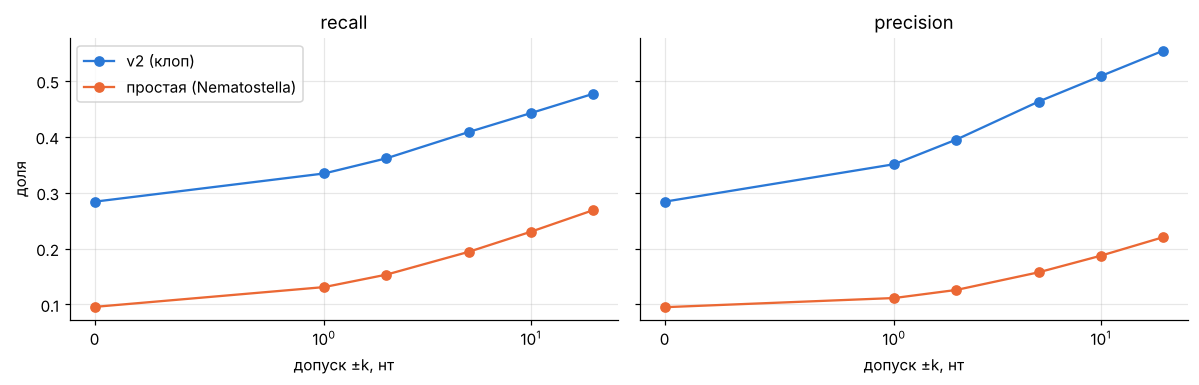

**Вывод.** v2 (клоп): найдено 28% стартов строго и 41% при допуске ±5 нт; простая (Nematostella): найдено 10% стартов строго и 19% при допуске ±5 нт. Сдвиг по позиции объясняет только часть пропусков.

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, key in zip(ax, ("recall", "precision")):
    for n, d in M.items(): a.plot([t["k"] for t in d["tolerance"]], [t[key] for t in d["tolerance"]], "o-", color=C[n], label=n)
    a.set(xlabel="допуск ±k, нт", title=key); a.set_xscale("symlog", linthresh=1)
ax[0].set_ylabel("доля"); ax[0].legend(); plt.tight_layout(); plt.show()
t = {n: (d["tolerance"][0]["recall"], d["tolerance"][3]["recall"]) for n, d in M.items()}
display(Markdown("**Вывод.** " + "; ".join(f"{n}: найдено {pct(a)} стартов строго и {pct(b)} при допуске ±5 нт" for n, (a, b) in t.items()) + ". Сдвиг по позиции объясняет только часть пропусков."))

## 2. Пропуски по силе старта
**Метод.** Старты делятся на бины по суммарному счёту реплик; доля пропущенных = 1 − найдено/стартов, строго (k=0) и с допуском ±5 нт. Без подвыборки. Код: блок «доля пропусков».

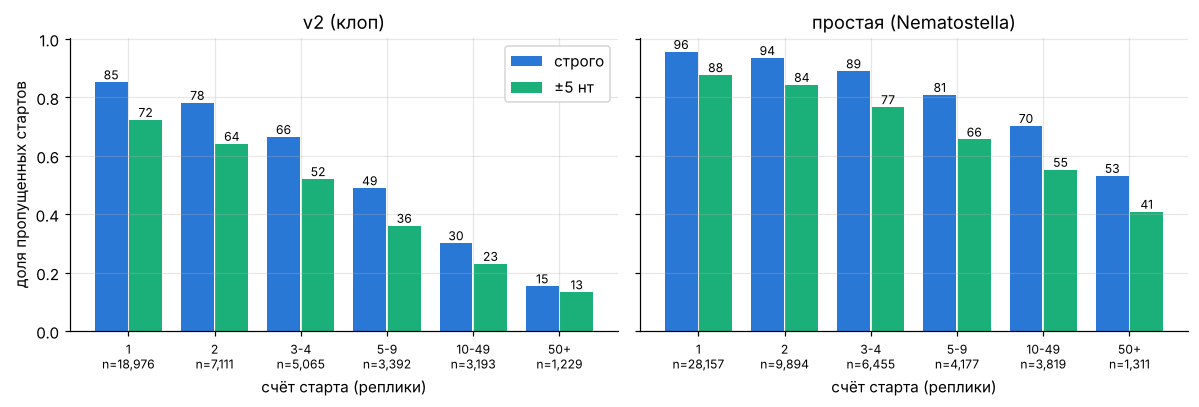

**Вывод.** Счёт 1: пропущено 85% (v2) и 96% (простая); счёт 50+: 15% и 53%. Доля стартов со счётом 1: 49% и 52%.

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, (n, d) in zip(ax, M.items()):
    L = [b["label"] for b in d["strength"]]; x = np.arange(len(L))
    for off, key, c, lab in ((-.2, "fn_k0", "#2a78d6", "строго"), (.2, "fn_k5", "#1baf7a", "±5 нт")):
        bars = a.bar(x + off, [b[key] for b in d["strength"]], .38, color=c, label=lab)
        for r, b in zip(bars, d["strength"]): a.text(r.get_x() + r.get_width() / 2, r.get_height() + .01, f"{100*b[key]:.0f}", ha="center", fontsize=8)
    a.set_xticks(x, [f"{l}\nn={b['n']:,}" for l, b in zip(L, d["strength"])], fontsize=8); a.set_title(n); a.set_xlabel("счёт старта (реплики)")
ax[0].set_ylabel("доля пропущенных стартов"); ax[0].legend(); plt.tight_layout(); plt.show()
g = lambda d, i: d["strength"][i]["fn_k0"]
display(Markdown(f"**Вывод.** Счёт 1: пропущено {pct(g(V,0))} (v2) и {pct(g(S,0))} (простая); счёт 50+: {pct(g(V,5))} и {pct(g(S,5))}. Доля стартов со счётом 1: {pct(V['meta']['n_gt1']/V['meta']['N_starts'])} и {pct(S['meta']['n_gt1']/S['meta']['N_starts'])}."))

## 3. Одиночные и кластерные старты
**Метод.** Для каждого старта считаем число других стартов в ±50 нт (накопленные суммы по вектору позиций). Группы: 0, 1–3, 4–10, 11+. Код: блок «одиночные».

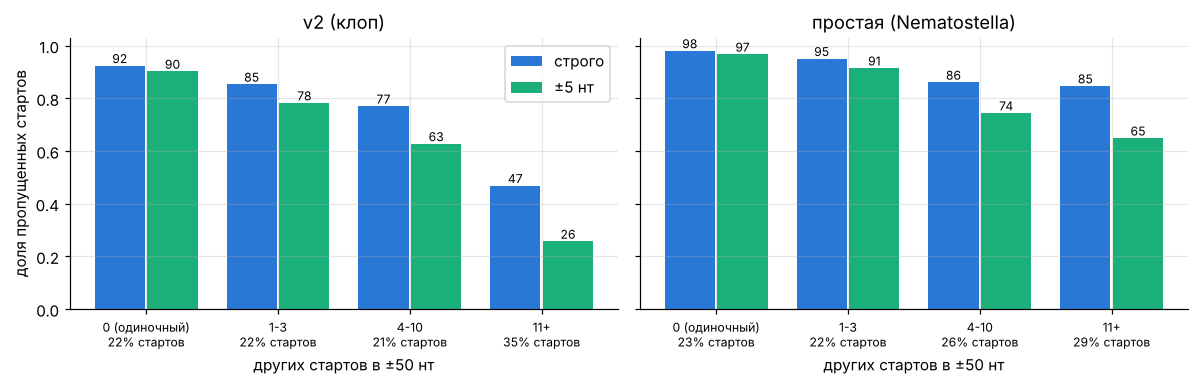

**Вывод.** Одиночные старты: 22% стартов v2 (пропущено 92%) и 23% простой (пропущено 98%); в кластерах 11+ пропущено 47% и 85%.

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, (n, d) in zip(ax, M.items()):
    L = [c["label"] for c in d["cluster"]]; x = np.arange(len(L))
    for off, key, c, lab in ((-.2, "fn_k0", "#2a78d6", "строго"), (.2, "fn_k5", "#1baf7a", "±5 нт")):
        bars = a.bar(x + off, [c_[key] for c_ in d["cluster"]], .38, color=c, label=lab)
        for r, c_ in zip(bars, d["cluster"]): a.text(r.get_x() + r.get_width() / 2, r.get_height() + .01, f"{100*c_[key]:.0f}", ha="center", fontsize=8)
    a.set_xticks(x, [f"{l}\n{pct(c['share'])} стартов" for l, c in zip(L, d["cluster"])], fontsize=8); a.set_title(n); a.set_xlabel("других стартов в ±50 нт")
ax[0].set_ylabel("доля пропущенных стартов"); ax[0].legend(); plt.tight_layout(); plt.show()
display(Markdown(f"**Вывод.** Одиночные старты: {pct(V['cluster'][0]['share'])} стартов v2 (пропущено {pct(V['cluster'][0]['fn_k0'])}) и {pct(S['cluster'][0]['share'])} простой (пропущено {pct(S['cluster'][0]['fn_k0'])}); в кластерах 11+ пропущено {pct(V['cluster'][3]['fn_k0'])} и {pct(S['cluster'][3]['fn_k0'])}."))

## 4. Precision–recall
**Метод.** Все старты + случайные 2 млн не-стартов с весом (число негативов/2 млн); позиции сортируются по предсказанию, считаются взвешенные TP и FP; 400 точек. Пунктир: случайный уровень. AUPRC строгий, по позициям, поэтому ниже официального. Код: блок «PR».

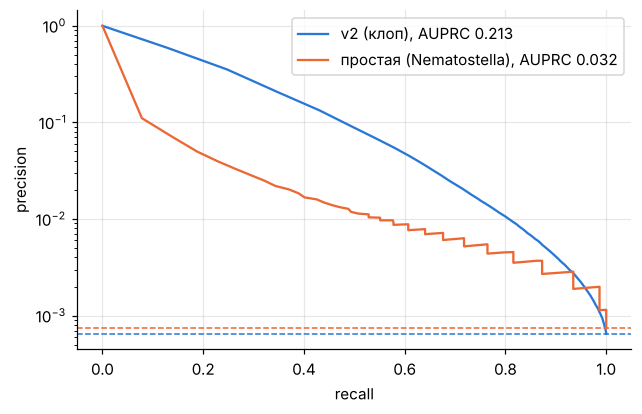

**Вывод.** Обе кривые выше случайного уровня (пунктир): v2 (клоп): AUPRC 0.213 при случайном 6.5e-04; простая (Nematostella): AUPRC 0.032 при случайном 7.4e-04.

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for n, d in M.items():
    ax.plot(d["pr"]["recall"], d["pr"]["precision"], color=C[n], label=f"{n}, AUPRC {d['pr']['auprc']:.3f}"); ax.axhline(d["pr"]["baseline"], color=C[n], ls="--", lw=1)
ax.set(xlabel="recall", ylabel="precision", yscale="log"); ax.legend(); plt.show()
display(Markdown("**Вывод.** Обе кривые выше случайного уровня (пунктир): " + "; ".join(f"{n}: AUPRC {d['pr']['auprc']:.3f} при случайном {d['pr']['baseline']:.1e}" for n, d in M.items()) + "."))

## 5. Предсказание против реального счёта
**Метод.** Предсказание → перцентиль среди всех оцениваемых позиций (по 1 млн случайных значений). Для каждого бина счёта (0 = нет старта) до 200 000 позиций; слева квантили 5/25/50/75/95%, справа распределение перцентиля (20 столбцов), доля внутри строки. Код: блок «распределение предсказаний».

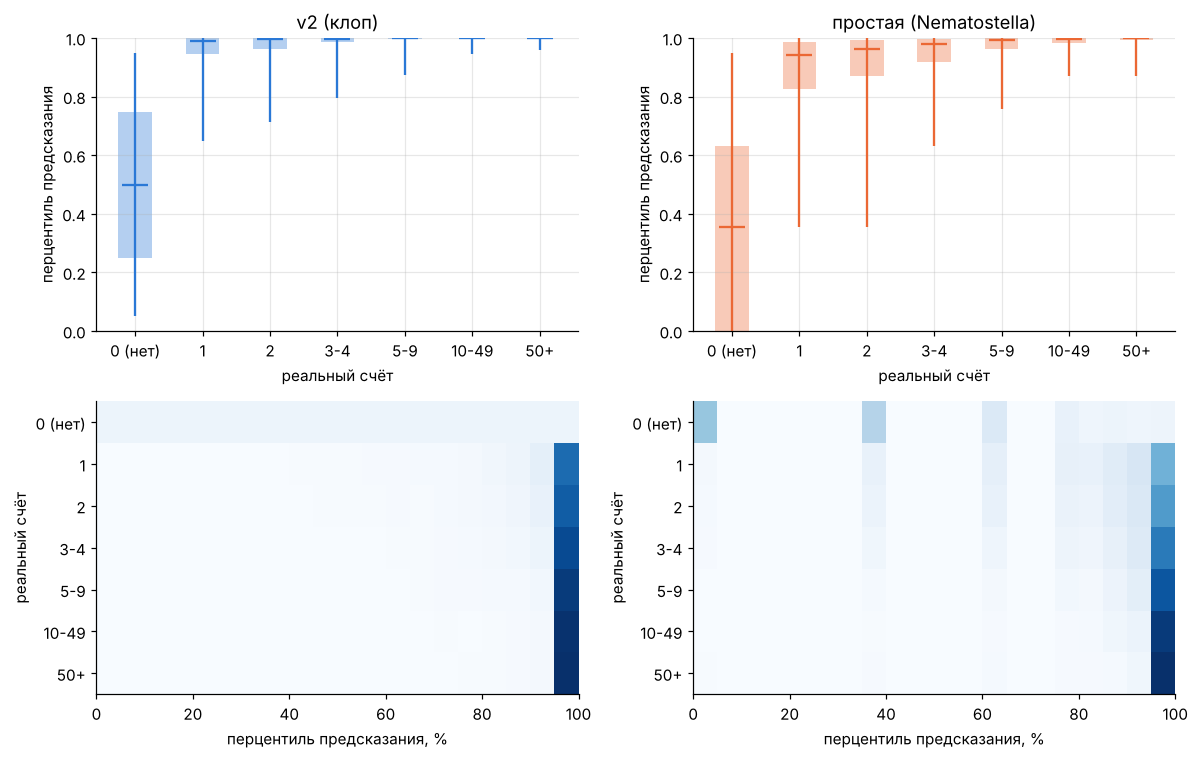

**Вывод.** Медианный перцентиль предсказания: v2 — фон 50%, счёт 1 99%, счёт 50+ 100%; простая — фон 36%, счёт 1 94%, счёт 50+ 100%. Предсказание растёт со счётом, и даже слабые старты лежат в верхнем ~1% позиций, но порог верхних N — это верхние 0.065% (v2) и 0.074% (простая) позиций, поэтому в строгий критерий попадает лишь малая часть: проблема в точности ранга внутри верхнего 1%, а не в том, что слабые старты неотличимы от фона.

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for j, (n, d) in enumerate(M.items()):
    q = np.array([r["q"] for r in d["pred_by_gt"]]); L = [r["label"] for r in d["pred_by_gt"]]; x = np.arange(len(L))
    a = ax[0, j]; a.vlines(x, q[:, 0], q[:, 4], color=C[n]); a.bar(x, q[:, 3] - q[:, 1], bottom=q[:, 1], width=.5, color=C[n], alpha=.35); a.scatter(x, q[:, 2], color=C[n], zorder=3, marker="_", s=300)
    a.set_xticks(x, L); a.set(title=n, xlabel="реальный счёт", ylabel="перцентиль предсказания", ylim=(0, 1))
    z = np.array(d["hist2d"]["z"]); im = ax[1, j].imshow(z, aspect="auto", cmap="Blues", extent=(0, 100, len(L), 0))
    ax[1, j].set_yticks(np.arange(len(L)) + .5, d["hist2d"]["rows"]); ax[1, j].set(xlabel="перцентиль предсказания, %", ylabel="реальный счёт"); ax[1, j].grid(False)
plt.tight_layout(); plt.show()
md_ = lambda d: [r["q"][2] for r in d["pred_by_gt"]]
display(Markdown(f"**Вывод.** Медианный перцентиль предсказания: v2 — фон {pct(md_(V)[0])}, счёт 1 {pct(md_(V)[1])}, счёт 50+ {pct(md_(V)[6])}; простая — фон {pct(md_(S)[0])}, счёт 1 {pct(md_(S)[1])}, счёт 50+ {pct(md_(S)[6])}. Предсказание растёт со счётом, и даже слабые старты лежат в верхнем ~1% позиций, но порог верхних N — это верхние {pct(V['meta']['N_starts']/V['meta']['N_scored'],3)} (v2) и {pct(S['meta']['N_starts']/S['meta']['N_scored'],3)} (простая) позиций, поэтому в строгий критерий попадает лишь малая часть: проблема в точности ранга внутри верхнего 1%, а не в том, что слабые старты неотличимы от фона."))

## 6. Признаки последовательности: TP, FN, FP и фон
**Метод.** Окно ±100 нт (направление цепи). GC — доля G+C; CpG o/e = CpG/(C·G/длина); «строчные» — доля нуклеотидов в мягко замаскированных повторах; энтропия 3-меров (бит); соседние старты в ±50. Сравнение групп: тест Манна–Уитни (p) и AUC = P(значение в первой группе > во второй), AUC≈0.5 — различий нет. Код: блок «группы для признаков».

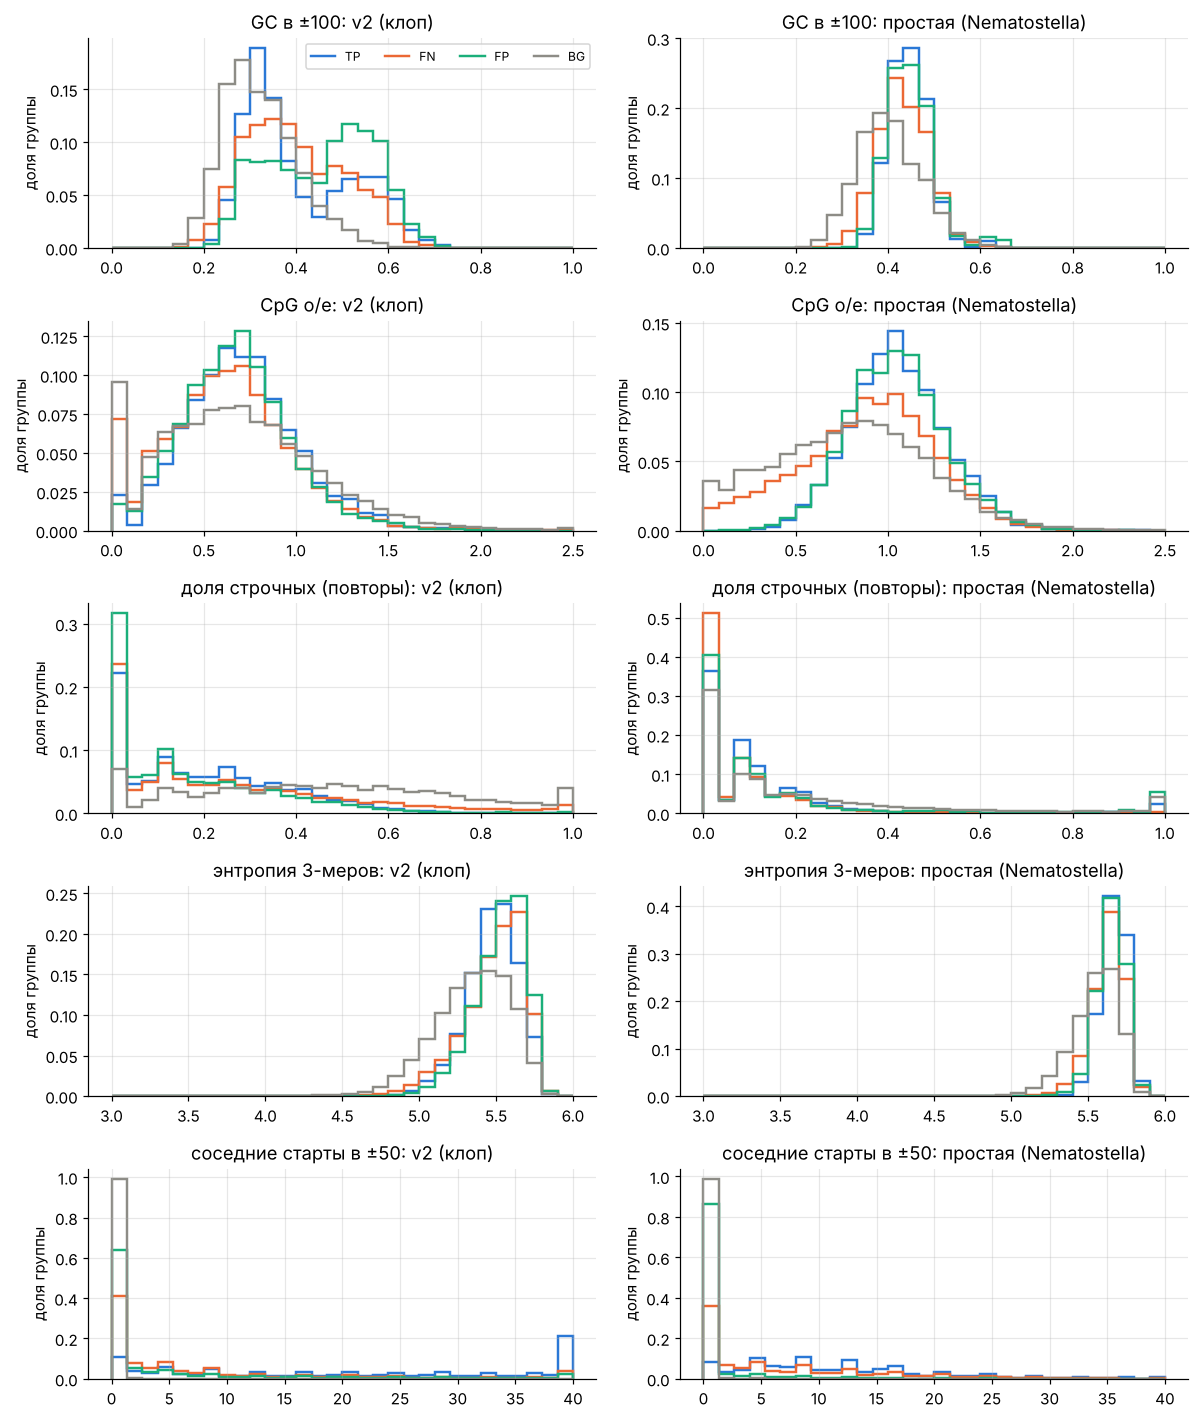

,модель,признак,медиана TP,медиана FN,медиана FP,медиана BG,FN vs TP,FP vs BG,FP vs TP
0,v2 (клоп),GC в ±100,0.363,0.383,0.473,0.313,"AUC 0.50, p=6.3e-01","AUC 0.82, p=0.0e+00","AUC 0.62, p=6.2e-269"
1,v2 (клоп),CpG o/e,0.692,0.618,0.666,0.653,"AUC 0.43, p=1.9e-98","AUC 0.51, p=6.6e-03","AUC 0.47, p=1.3e-19"
2,v2 (клоп),доля строчных (повторы),0.184,0.199,0.114,0.453,"AUC 0.53, p=8.7e-24","AUC 0.19, p=0.0e+00","AUC 0.43, p=9.5e-108"
3,v2 (клоп),энтропия 3-меров,5.488,5.524,5.552,5.370,"AUC 0.54, p=1.5e-26","AUC 0.73, p=0.0e+00","AUC 0.59, p=3.4e-161"
4,v2 (клоп),соседние старты в ±50,21.000,3.000,0.000,0.000,"AUC 0.23, p=0.0e+00","AUC 0.72, p=0.0e+00","AUC 0.16, p=0.0e+00"
5,простая (Nematostella),GC в ±100,0.443,0.433,0.443,0.398,"AUC 0.43, p=9.9e-55","AUC 0.71, p=0.0e+00","AUC 0.50, p=3.1e-01"
6,простая (Nematostella),CpG o/e,1.043,0.910,1.039,0.802,"AUC 0.36, p=3.9e-203","AUC 0.69, p=0.0e+00","AUC 0.49, p=2.1e-02"
7,простая (Nematostella),доля строчных (повторы),0.095,0.015,0.090,0.114,"AUC 0.42, p=1.5e-83","AUC 0.42, p=5.9e-158","AUC 0.50, p=8.3e-01"
8,простая (Nematostella),энтропия 3-меров,5.673,5.642,5.658,5.567,"AUC 0.40, p=1.7e-110","AUC 0.71, p=0.0e+00","AUC 0.45, p=8.1e-34"
9,простая (Nematostella),соседние старты в ±50,10.000,4.000,0.000,0.000,"AUC 0.32, p=0.0e+00","AUC 0.58, p=0.0e+00","AUC 0.07, p=0.0e+00"


**Вывод.** GC: FN vs TP AUC 0.50 (v2) и 0.43 (простая); FP vs фон AUC 0.82 и 0.71. CpG o/e: FP vs фон AUC 0.51 и 0.69. Различия между FN и TP по композиции малы; ложные срабатывания сильнее отличаются от фона.

In [7]:
FN_ = {"gc": "GC в ±100", "cpg_oe": "CpG o/e", "lower": "доля строчных (повторы)", "ent3": "энтропия 3-меров", "n_starts_pm50": "соседние старты в ±50"}
fig, ax = plt.subplots(len(FN_), 2, figsize=(11, 2.6 * len(FN_)))
for i, (f, name) in enumerate(FN_.items()):
    for j, (n, d) in enumerate(M.items()):
        fd = d["features"][f]; lo, hi = fd["range"]; edges = np.linspace(lo, hi, 31)
        for g_ in GC: ax[i, j].stairs(fd["hist"][g_], edges, color=GC[g_], lw=1.6, label=g_)
        ax[i, j].set(title=f"{name}: {n}", ylabel="доля группы")
ax[0, 0].legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()
import pandas as pd
rows = []
for n, d in M.items():
    for f, name in FN_.items():
        q = d["features"][f]; rows.append({"модель": n, "признак": name, **{f"медиана {g_}": round(q["median"][g_], 3) for g_ in GC}, **{k.replace("_vs_", " vs "): f"AUC {q[k]['auc']:.2f}, p={q[k]['p']:.1e}" for k in ("FN_vs_TP", "FP_vs_BG", "FP_vs_TP")}})
display(pd.DataFrame(rows))
gv, gs, cv, cs_ = V["features"]["gc"], S["features"]["gc"], V["features"]["cpg_oe"], S["features"]["cpg_oe"]
display(Markdown(f"**Вывод.** GC: FN vs TP AUC {gv['FN_vs_TP']['auc']:.2f} (v2) и {gs['FN_vs_TP']['auc']:.2f} (простая); FP vs фон AUC {gv['FP_vs_BG']['auc']:.2f} и {gs['FP_vs_BG']['auc']:.2f}. CpG o/e: FP vs фон AUC {cv['FP_vs_BG']['auc']:.2f} и {cs_['FP_vs_BG']['auc']:.2f}. Различия между FN и TP по композиции малы; ложные срабатывания сильнее отличаются от фона."))

## 7. Нуклеотиды вокруг позиции старта (−10…+10)
**Метод.** Частоты A, C, G, T в 21 позиции (направление цепи, 0 = позиция старта) в выборке каждой группы; окна со строчными буквами (повторы) или N пропущены, поэтому n меньше размера группы. Код: блок «nuc» и «динуклеотид».

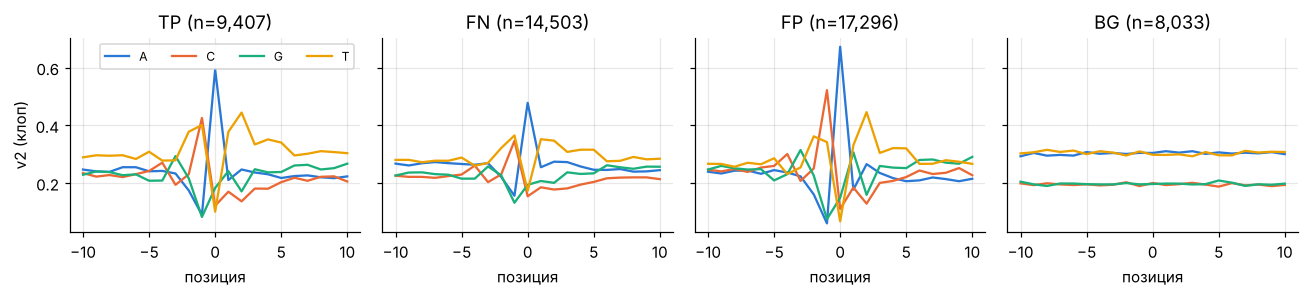

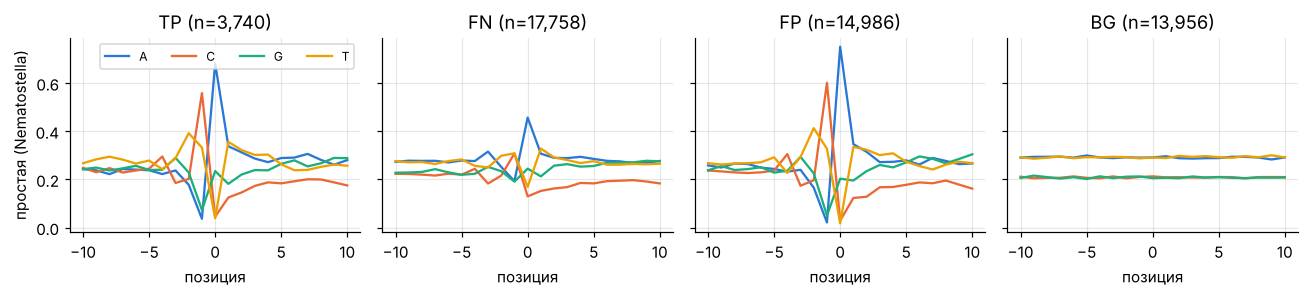

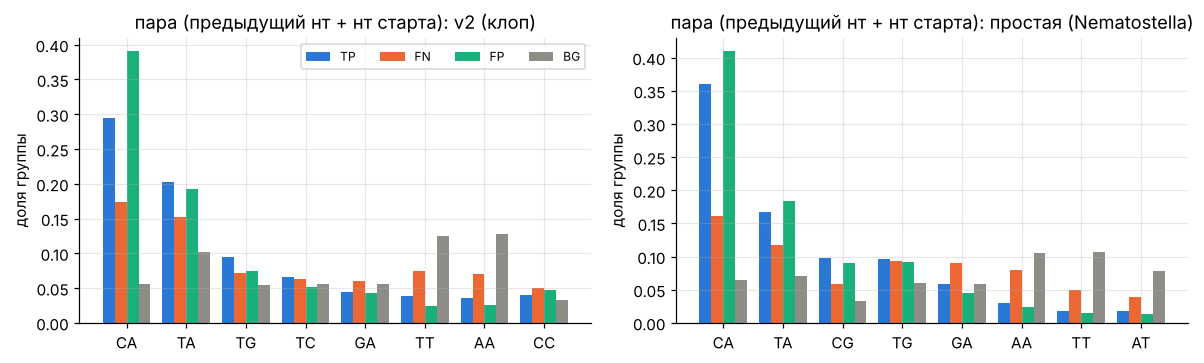

**Вывод.** Пара CA в позиции старта: v2 — TP 29%, FP 39%, фон 6%; простая — TP 36%, FP 41%, фон 6%. Вероятно, это Inr-подобный мотив (пиримидин–A): модели ставят высокий счёт на нём и там ошибаются без старта (гипотеза: нужна проверка по логотипу).

In [8]:
BC = {"A": "#2a78d6", "C": "#eb6834", "G": "#1baf7a", "T": "#eda100"}
for n, d in M.items():
    fig, ax = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
    for a, g_ in zip(ax, GC):
        z = np.array(d["nuc"][g_])
        for i, b in enumerate("ACGT"): a.plot(range(-10, 11), z[:, i], color=BC[b], label=b)
        a.set_title(f"{g_} (n={d['nuc_n'][g_]:,})"); a.set_xlabel("позиция")
    ax[0].set_ylabel(n); ax[0].legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, (n, d) in zip(ax, M.items()):
    top = [k for k in dict.fromkeys(k for g_ in GC for k, _ in sorted(d["dinuc"][g_].items(), key=lambda x: -x[1])[:5]) if "N" not in k][:8]; x = np.arange(len(top))
    for i, g_ in enumerate(GC): a.bar(x + (i - 1.5) * .2, [d["dinuc"][g_].get(k, 0) for k in top], .2, color=GC[g_], label=g_)
    a.set_xticks(x, top); a.set_title(f"пара (предыдущий нт + нт старта): {n}"); a.set_ylabel("доля группы")
ax[0].legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()
dd = lambda d, g_, k: pct(d["dinuc"][g_].get(k, 0))
display(Markdown(f"**Вывод.** Пара CA в позиции старта: v2 — TP {dd(V,'TP','CA')}, FP {dd(V,'FP','CA')}, фон {dd(V,'BG','CA')}; простая — TP {dd(S,'TP','CA')}, FP {dd(S,'FP','CA')}, фон {dd(S,'BG','CA')}. Вероятно, это Inr-подобный мотив (пиримидин–A): модели ставят высокий счёт на нём и там ошибаются без старта (гипотеза: нужна проверка по логотипу)."))

## Что можно исправить
* **Слабые и одиночные старты:** взвешивание по счёту/плотности стартов в обучении, оценка по пикам, а не по позициям.
* **Сдвиг по позиции:** сглаживать предсказание по ±2–5 нт или предсказывать пик, затем позицию внутри него.
* **Ложные срабатывания:** признаки «плотность CpG ±100» и «режим промотора» (шаг 7 простой модели), штраф за GC/CpG-богатые окна без сигнала.
* **Потолок качества:** сравнить с воспроизводимостью реплик r1/r2 — часть пропусков может быть шумом самих данных.

**Ограничения:** анализ по позициям, не по пикам; критерий «верхние N» строгий; v2 — только hold-out клопа (2 сида, не ансамбль из 4); простая модель — другой вид. Идея интерпретируемой модели от пользователя в разбор не вошла (текст не получен).